# C08c — GLTR features: competitors, RAFT, NS10 and NS11

Run in a fresh kernel inside `reproduction/`. Reads the same ten saved arms as C08b: OG, NS10, six C08 competitors, OG→RAFT and NS11. All arms must contain the same 54 sources. No text generation or language-model training.

**Detector:** reuse `C07c_GLTR_RAID_OG_NS10_v1/classifiers.joblib`: the saved original RAID-trained logistic classifier and train-only scaler. GLTR itself is a visualization method, not this binary classifier. Features are the four GPT-2 rank fractions (1–10, 11–100, 101–1000, >1000). Frozen FP32 GPT-2, first 1024 tokens, first token excluded, no artificial BOS; rank is one plus the number of strictly greater logits. This carries forward C07c's exact extraction algorithm.

Existing compatible feature caches are read without modification. The current runtime is included in extraction identity; if it differs, required features are recomputed under the current runtime in C08c, while the classifier and scaler remain frozen. No contract overwriting or package downgrades. Completed feature records survive interruption. One GPT-2 is loaded at a time; classifier adaptation runs on CPU.

**Adaptation:** select every non-OG arm with full54 frozen AUROC strictly below .8, including NS10, RAFT or NS11 when eligible. Reuse the saved C07b random twenty/thirty-four split and verify agreement with C07c. Each selected arm is fitted separately on original RAID training features plus twenty own-arm positive examples; original scaler stays fixed. The frozen classifier already is the RAID-only control. Adapted heads and numerical fitting inputs are saved independently and reused on resume.

Full-cohort selection includes the eventual 34 holdout scores; this is an exploratory conditional adaptation comparison. Source split, clean validation/test humans and within-arm fitting/evaluation separation are maintained. Bootstrap intervals condition on fitted models, the split and human references. No inference of universal robustness or human-band matching from below-chance AUROC alone.

**Plots:** one combined full54 staircase and one combined selected-arm frozen/adapted staircase, each with full, low-FPR and very-low-FPR panels. All thresholds are chosen from validation-human scores using strict `score > threshold`, consistently with C08a/b. This plotting convention differs from C07c's exact empirical ROC drawing and `>=` operating-point code; weighted AUROC remains the same statistic. Human-domain weights match 54 or 34 cases as appropriate. CSV scores, human weights, operating points, paired changes, and PNG/PDF exports are saved. Figures also go to `reproduction/figures/`.

NS11 remains an exploratory compatibility output with known quality caveats; limited reproductions remain distinct from released 4B adapters. RAFT and NS11 used RoBERTa guidance, not this GLTR head.

Reference: [Gehrmann et al., GLTR (2019)](https://aclanthology.org/P19-3019/). Input paths are editable in the first cell. No pip commands are necessary if the earlier GLTR environment works.


## Setup

In [1]:
from pathlib import Path
import os,json,hashlib,tempfile,gc,copy,inspect,fcntl,importlib.metadata
from contextlib import contextmanager
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoTokenizer,AutoModelForSequenceClassification,Trainer,DataCollatorWithPadding,set_seed
from transformers.trainer_utils import get_last_checkpoint
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
    if (p/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1').exists()),None)
assert ROOT is not None,'Open inside reproduction/.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C07=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1'
FROZEN=C07/'best_model'
REF_AD=C07/'adaptation20_34_seed20260923'
C08=ROOT/'results/causal/C08_Ghostbuster_only_RAID54_v1'
OUT=ROOT/'results/causal/C08c_GLTR_competitors_RAFT_NS11_v1'
OUT.mkdir(parents=True,exist_ok=True)
MAX_TOKENS=512
FILES={
 'NS10':ROOT/'results/causal/C06b_NEW_steps5_10_v1/NS10_texts.csv',
 'HIP_limited':C08/'HIP_RAID_0.6B_texts.csv',
 'MASH_limited':C08/'MASH_RAID_GB_texts.csv',
 'UTS_SYNTH_limited':C08/'UTS_SYNTH_RECON_texts.csv',
 'UTS_STREAM_limited':C08/'UTS_STREAM_RECON_texts.csv',
 'HIP_released4B':C08/'released_checkpoints_v1/HIP_RELEASED_4B_texts.csv',
 'StealthRL_released4B':C08/'released_checkpoints_v1/StealthRL_RELEASED_4B_texts.csv',
 'OG_RAFT':ROOT/'results/causal/R01_published_local_v3/RAFT_adaptation20_34/RAFT_texts54.csv',
 'NS11':ROOT/'results/causal/R11_NS10_RAFT_v1/NS11_texts.csv',
}
GLTR=ROOT/'results/causal/C07c_GLTR_RAID_OG_NS10_v1'
assert (GLTR/'classifiers.joblib').exists(),'Missing saved C07c classifier.'
import joblib,warnings
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from transformers import AutoModelForCausalLM
FEATURES=['rank_1_10','rank_11_100','rank_101_1000','rank_gt_1000']

def sha(x):return hashlib.sha256(str(x).encode()).hexdigest()
def file_sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
def write_json(p,x):
    p.parent.mkdir(parents=True,exist_ok=True)
    fd,t=tempfile.mkstemp(dir=p.parent)
    try:
        with os.fdopen(fd,'w') as f:json.dump(x,f,indent=2,sort_keys=True);f.flush();os.fsync(f.fileno())
        os.replace(t,p)
    finally:
        if os.path.exists(t):os.unlink(t)
def freeze(p,x):
    if p.exists():assert json.loads(p.read_text())==x,f'Inputs/settings changed: {p}. Keep this run; choose a new OUT.'
    else:write_json(p,x)
def csv(f,p):
    p.parent.mkdir(parents=True,exist_ok=True);t=p.with_suffix('.tmp');f.to_csv(t,index=False);os.replace(t,p)
def release():gc.collect();torch.cuda.empty_cache()
@contextmanager
def lock():
    with (OUT/'run.lock').open('a') as f:
        fcntl.flock(f,fcntl.LOCK_EX|fcntl.LOCK_NB)
        try:yield
        finally:fcntl.flock(f,fcntl.LOCK_UN)
def fingerprint(p):
    files=sorted(Path(p).glob('*.safetensors')) or sorted(Path(p).glob('pytorch_model*.bin'))
    assert files,f'Missing weights: {p}'
    return {x.name:file_sha(x) for x in [Path(p)/'config.json',*files]}
RUNTIME={k:importlib.metadata.version(k) for k in ['torch','transformers','accelerate']}
print('Results:',OUT,'\nRuntime:',RUNTIME)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results: ../results/causal/C08c_GLTR_competitors_RAFT_NS11_v1 
Runtime: {'torch': '2.13.0+cu130', 'transformers': '4.44.2', 'accelerate': '0.34.2'}


## Saved text and split validation

In [2]:
missing=[str(p) for p in FILES.values() if not p.exists()]
assert not missing,'Missing exports; set FILES to your saved paths:\n'+'\n'.join(missing)
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].merge(corpus[['source_id','text']],on='source_id',validate='one_to_one')
raid['text_sha']=raid.text.map(sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all()
raid['group']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('group').split.nunique().eq(1).all()
ns=pd.read_csv(FILES['NS10'],keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
case_ids=ns.case_id.astype(str).tolist();rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)
frames={'OG':og}
for arm,path in FILES.items():
    f=pd.read_csv(path,keep_default_na=False)
    assert len(f)==54 and f.case_id.is_unique and set(f.case_id)==set(case_ids),f'{arm}: require all 54 unique case IDs; no silent subset.'
    f=f.set_index('case_id').loc[case_ids].reset_index()
    assert f.source_id.tolist()==ns.source_id.tolist() and f.domain.tolist()==ns.domain.tolist()
    assert f.text.str.strip().ne('').all()
    if 'text_sha' in f:assert f.text_sha.eq(f.text.map(sha)).all()
    frames[arm]=f[['case_id','source_id','domain','text']].copy()
for arm,f in frames.items():f['arm']=arm;f['label']=1;f['text_sha']=f.text.map(sha)
H=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].copy()
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
split=json.loads((REF_AD/'split.json').read_text())
chosen=sorted(map(str,split['adaptation_cases']));held=sorted(map(str,split['test_cases']))
assert len(chosen)==20 and len(held)==34 and not set(chosen)&set(held)
assert set(chosen+held)==set(case_ids)
freeze(OUT/'split.json',split)
roles=ns[['case_id','source_id','domain']].copy();roles['role']=np.where(roles.case_id.isin(chosen),'adaptation','heldout')
csv(roles,OUT/'case_roles.csv')
for arm,f in frames.items():
    if arm=='OG':continue
    fit=pd.concat([tr,f.loc[f.case_id.isin(chosen)]])
    evalu=pd.concat([va,H,f.loc[f.case_id.isin(held)]])
    assert not set(fit.text_sha)&set(evalu.text_sha),f'Exact fitting/evaluation text overlap: {arm}'
freeze(OUT/'inputs.json',dict(texts={arm:f[['case_id','text_sha']].to_dict('records') for arm,f in frames.items()},
    raid=raid[['source_id','split','label','text_sha']].to_dict('records')))

SEED=20260923
saved=joblib.load(GLTR/'classifiers.joblib')
assert saved['features']==FEATURES
scaler=saved['scaler'];frozen=saved['heads']['Frozen / RAID-only']
assert list(frozen.classes_)==[0,1]
assert set(saved['split']['adaptation_cases'])==set(chosen) and set(saved['split']['test_cases'])==set(held),'C07c and RoBERTa split differ.'
freeze(OUT/'classifier_provenance.json',dict(source=str(GLTR/'classifiers.joblib'),sha=file_sha(GLTR/'classifiers.joblib'),features=FEATURES))
del meta,corpus,rm;release()


## Resumable GPT-2 rank extraction and frozen scoring

In [3]:
with lock():
    pin=json.loads((GLTR/'model_pin.json').read_text())
    import transformers
    spec={**pin,'max_tokens':1024,'dtype':'float32','first_token':'excluded','rank':'1 + number of strictly greater logits','version':1,'transformers':transformers.__version__,'torch':str(torch.__version__)}
    freeze(OUT/'extractor.json',spec)
    (OUT/'features').mkdir(exist_ok=True)
    def feature_path(text):
        name=sha(json.dumps(spec,sort_keys=True)+sha(text))+'.json'
        old=GLTR/'features'/name
        return old if old.exists() else OUT/'features'/name
    all_texts=list(dict.fromkeys(raid.text.tolist()+[t for f in frames.values() for t in f.text]))
    pending=[t for t in all_texts if not feature_path(t).exists()]
    print(f'{len(all_texts)-len(pending)}/{len(all_texts)} cached; {len(pending)} remaining',flush=True)
    model=tok=None
    try:
        if pending:
            device='cuda' if torch.cuda.is_available() else 'cpu'
            tok=AutoTokenizer.from_pretrained(pin['model'],revision=pin['revision'])
            model=AutoModelForCausalLM.from_pretrained(pin['model'],revision=pin['revision'],torch_dtype=torch.float32,attn_implementation='eager').to(device).eval()
        for i,text in enumerate(pending,1):
            ids=tok.encode(text,add_special_tokens=False,truncation=False)
            total=len(ids);ids=ids[:1024]
            if len(ids)<2:raise ValueError('Document has fewer than two GPT-2 tokens: '+sha(text))
            batch=torch.tensor([ids],device=device)
            counts=np.zeros(4,dtype=np.int64)
            with torch.inference_mode():
                logits=model(input_ids=batch,use_cache=False).logits[0,:-1]
                for start in range(0,len(ids)-1,32):
                    z=logits[start:start+32].float()
                    target=batch[0,start+1:start+1+len(z)]
                    actual=z.gather(1,target[:,None])
                    ranks=1+(z>actual).sum(dim=1)
                    counts+=np.array([(ranks<=10).sum().item(),((ranks>10)&(ranks<=100)).sum().item(),((ranks>100)&(ranks<=1000)).sum().item(),(ranks>1000).sum().item()])
                del logits,z,target,actual,ranks,batch
            assert counts.sum()==len(ids)-1
            record={'text_sha':sha(text),'total_tokens':total,'scored_tokens':len(ids)-1,'truncated':total>1024,**dict(zip(FEATURES,(counts/counts.sum()).tolist()))}
            write_json(feature_path(text),record)
            if i%10==0 or i==len(pending):print(f'{i}/{len(pending)} newly saved',flush=True)
    finally:
        del model,tok;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
    
    def augment(frame):
        records=[json.loads(feature_path(t).read_text()) for t in frame.text]
        for t,r in zip(frame.text,records):assert sha(t)==r['text_sha']
        return pd.concat([frame.reset_index(drop=True).drop(columns='text_sha',errors='ignore'),pd.DataFrame(records)],axis=1)
    trf=augment(tr);hf=augment(H)
    features={arm:augment(f) for arm,f in frames.items()}
    for arm,f in features.items():csv(f.drop(columns='text'),OUT/'features_export'/(arm+'.csv'))
    csv(trf.drop(columns='text'),OUT/'RAID_train_features.csv')
    csv(hf.drop(columns='text'),OUT/'human_features.csv')
    # Saved head/scaler remain frozen, even if runtime changed and features were recomputed.
    print('Reusing the saved C07c classifier and scaler; no baseline fitting.')
    summary=pd.DataFrame([dict(arm=a,cases=len(f),prefix_truncated=int(f.truncated.sum())) for a,f in features.items()])
    csv(summary,OUT/'truncation_summary.csv');display(summary)
    def scored_frame(head,f):
        out=f.drop(columns='text').copy()
        out['AI_score']=head.decision_function(scaler.transform(f[FEATURES]))
        return out
    humans=hf.assign(arm='Human',case_id='')
    frozen_scores=pd.concat([scored_frame(frozen,humans),*[scored_frame(frozen,f) for f in features.values()]],ignore_index=True)
    csv(frozen_scores,OUT/'frozen_all_scores.csv')


0/2304 cached; 2304 remaining


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


10/2304 newly saved
20/2304 newly saved
30/2304 newly saved
40/2304 newly saved
50/2304 newly saved
60/2304 newly saved
70/2304 newly saved
80/2304 newly saved
90/2304 newly saved
100/2304 newly saved
110/2304 newly saved
120/2304 newly saved
130/2304 newly saved
140/2304 newly saved
150/2304 newly saved
160/2304 newly saved
170/2304 newly saved
180/2304 newly saved
190/2304 newly saved
200/2304 newly saved
210/2304 newly saved
220/2304 newly saved
230/2304 newly saved
240/2304 newly saved
250/2304 newly saved
260/2304 newly saved
270/2304 newly saved
280/2304 newly saved
290/2304 newly saved
300/2304 newly saved
310/2304 newly saved
320/2304 newly saved
330/2304 newly saved
340/2304 newly saved
350/2304 newly saved
360/2304 newly saved
370/2304 newly saved
380/2304 newly saved
390/2304 newly saved
400/2304 newly saved
410/2304 newly saved
420/2304 newly saved
430/2304 newly saved
440/2304 newly saved
450/2304 newly saved
460/2304 newly saved
470/2304 newly saved
480/2304 newly saved
4

Token indices sequence length is longer than the specified maximum sequence length for this model (1038 > 1024). Running this sequence through the model will result in indexing errors


1880/2304 newly saved
1890/2304 newly saved
1900/2304 newly saved
1910/2304 newly saved
1920/2304 newly saved
1930/2304 newly saved
1940/2304 newly saved
1950/2304 newly saved
1960/2304 newly saved
1970/2304 newly saved
1980/2304 newly saved
1990/2304 newly saved
2000/2304 newly saved
2010/2304 newly saved
2020/2304 newly saved
2030/2304 newly saved
2040/2304 newly saved
2050/2304 newly saved
2060/2304 newly saved
2070/2304 newly saved
2080/2304 newly saved
2090/2304 newly saved
2100/2304 newly saved
2110/2304 newly saved
2120/2304 newly saved
2130/2304 newly saved
2140/2304 newly saved
2150/2304 newly saved
2160/2304 newly saved
2170/2304 newly saved
2180/2304 newly saved
2190/2304 newly saved
2200/2304 newly saved
2210/2304 newly saved
2220/2304 newly saved
2230/2304 newly saved
2240/2304 newly saved
2250/2304 newly saved
2260/2304 newly saved
2270/2304 newly saved
2280/2304 newly saved
2290/2304 newly saved
2300/2304 newly saved
2304/2304 newly saved
Reusing the saved C07c classifie

,arm,cases,prefix_truncated
0,OG,54,0
1,NS10,54,0
2,HIP_limited,54,6
3,MASH_limited,54,0
4,UTS_SYNTH_limited,54,2
5,UTS_STREAM_limited,54,0
6,HIP_released4B,54,0
7,StealthRL_released4B,54,0
8,OG_RAFT,54,1
9,NS11,54,0


## Full54 comparison and selection

,arm,detector,cases,AUROC,mean_AI_score
0,OG,Frozen,54,0.815979,0.650457
1,NS10,Frozen,54,0.506231,-0.696831
2,HIP_limited,Frozen,54,0.774764,0.543938
3,MASH_limited,Frozen,54,0.944855,1.546379
4,UTS_SYNTH_limited,Frozen,54,0.612100,-0.234844
5,UTS_STREAM_limited,Frozen,54,0.673365,-0.045455
6,HIP_released4B,Frozen,54,0.856354,0.756265
7,StealthRL_released4B,Frozen,54,0.309175,-2.479841
8,OG_RAFT,Frozen,54,0.320135,-1.476803
9,NS11,Frozen,54,0.096642,-2.721266


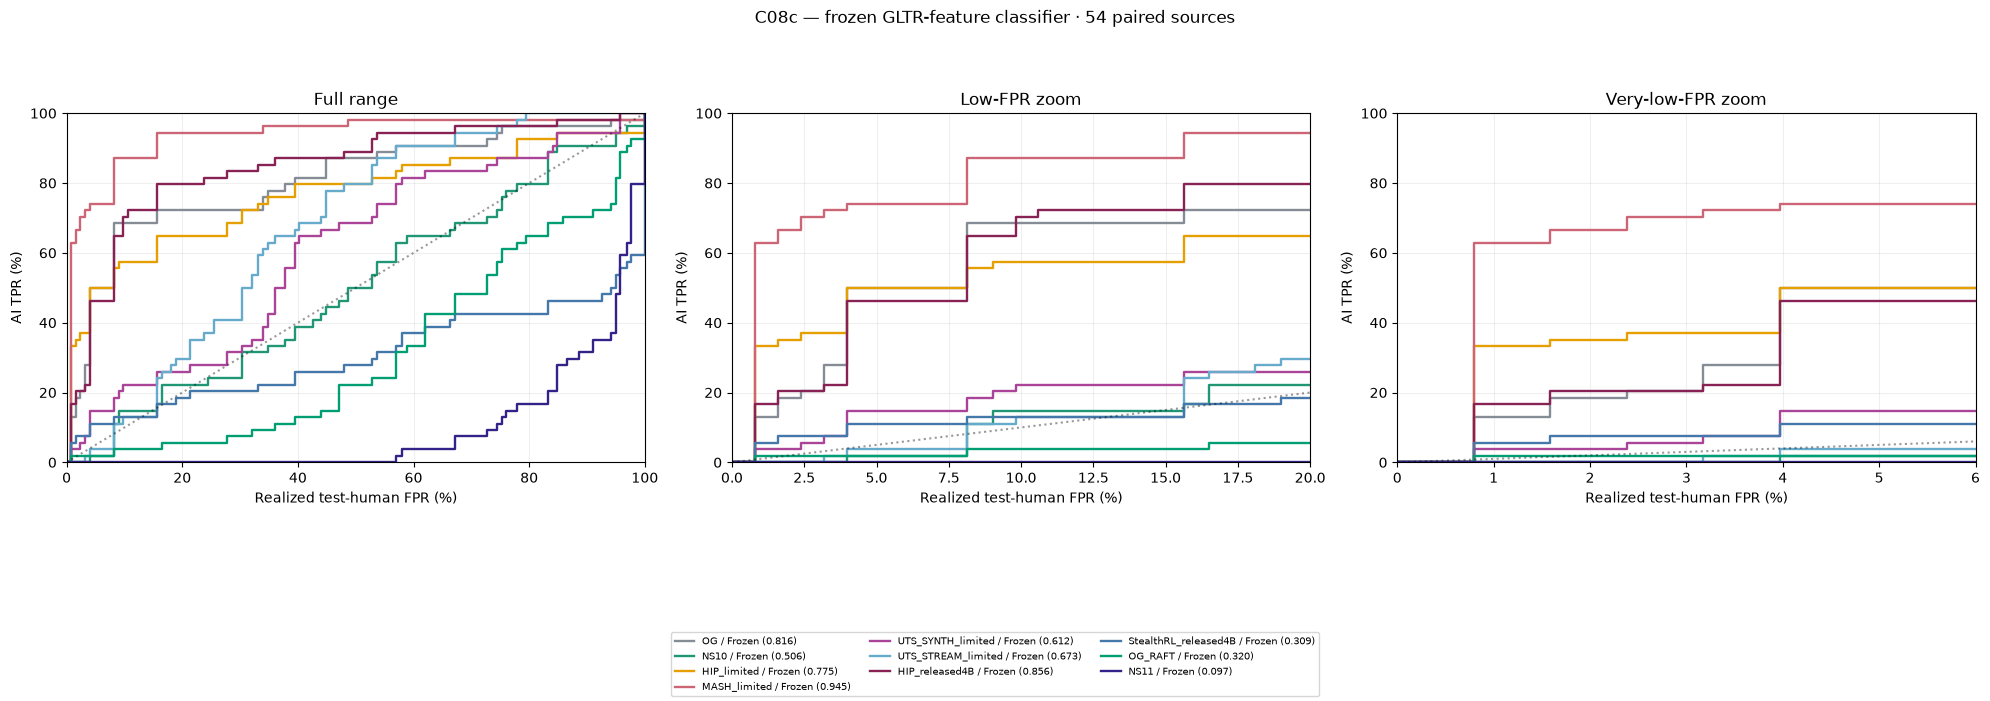

,arm,baseline,delta_AUROC,ci_low,ci_high
0,NS10,OG,-0.309748,-0.386140,-0.234434
1,HIP_limited,OG,-0.041216,-0.122889,0.039381
2,HIP_limited,NS10,0.268532,0.162718,0.367495
3,MASH_limited,OG,0.128876,0.053408,0.204835
4,MASH_limited,NS10,0.438624,0.355315,0.524587
5,UTS_SYNTH_limited,OG,-0.203879,-0.260754,-0.144979
6,UTS_SYNTH_limited,NS10,0.105869,0.034570,0.180192
7,UTS_STREAM_limited,OG,-0.142615,-0.218173,-0.064099
8,UTS_STREAM_limited,NS10,0.167133,0.079506,0.255450
9,HIP_released4B,OG,0.040375,-0.001100,0.090434


Own-arm adaptation: ['NS10', 'HIP_limited', 'UTS_SYNTH_limited', 'UTS_STREAM_limited', 'StealthRL_released4B', 'OG_RAFT', 'NS11']
Selection uses all 54 outcomes: the subsequent 34-case analysis is exploratory.


In [4]:
COLORS=dict(zip(frames,['#858C96','#209675','#E69F00','#CC6677','#AA4499','#66AACC','#882255','#4477AA','#009E73','#332288']))
def evaluate(scores,ids,detector):
    selected_scores=scores.loc[scores.case_id.isin(ids)]
    mix=ns.set_index('case_id').loc[ids].domain.value_counts(normalize=True)
    refs={}
    for splitname in ['validation','test']:
        f=scores.loc[scores.arm.eq('Human')&scores.split.eq(splitname)&scores.domain.isin(mix.index)].copy()
        counts=f.domain.value_counts();assert set(mix.index)<=set(counts.index)
        f['weight']=[mix[d]/counts[d] for d in f.domain];assert np.isclose(f.weight.sum(),1)
        refs[splitname]=f
    v,h=refs['validation'],refs['test'];vs=v.AI_score.to_numpy();hs=h.AI_score.to_numpy();w=h.weight.to_numpy()
    rows=[];curves=[];parts={};ops=[]
    for arm,f in selected_scores.groupby('arm',sort=False):
        f=f.set_index('case_id').loc[ids];a=f.AI_score.to_numpy()
        c=((a[:,None]>hs)+.5*(a[:,None]==hs))@w;parts[arm]=c
        row=dict(arm=arm,detector=detector,cases=len(ids),AUROC=float(c.mean()),mean_AI_score=float(a.mean()))
        rows.append(row);cuts=np.r_[np.inf,np.unique(vs)[::-1],-np.inf]
        st=pd.DataFrame(dict(arm=arm,detector=detector,threshold=cuts,
            calibration_FPR=[v.weight.to_numpy()[vs>x].sum() for x in cuts],
            test_FPR=[w[hs>x].sum() for x in cuts],TPR=[(a>x).mean() for x in cuts]))
        curves.append((arm,detector,st,row['AUROC']))
        for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1]:
            r=st.loc[st.calibration_FPR<=target+1e-12].iloc[-1].to_dict();ops.append(dict(target_FPR=target,**r))
    return pd.DataFrame(rows),curves,parts,pd.DataFrame(ops),refs

def plot(curves,title,stem):
    fig,axes=plt.subplots(1,3,figsize=(20,7))
    for ax,(xl,title2) in zip(axes,[((0,100),'Full range'),((0,20),'Low-FPR zoom'),((0,6),'Very-low-FPR zoom')]):
        for arm,det,st,value in curves:
            style={'Frozen':'-','RAID-only continuation':':','Own-arm adapted':'--'}[det]
            ax.step(100*st.test_FPR,100*st.TPR,where='post',color=COLORS[arm],ls=style,lw=1.7,
                label=f'{arm} / {det} ({value:.3f})')
        ax.plot([0,xl[1]],[0,xl[1]],'k:',alpha=.4)
        ax.set(xlim=xl,ylim=(0,100),title=title2,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
    handles,labels=axes[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',fontsize=7,ncol=3)
    fig.suptitle(title);fig.tight_layout(rect=[0,.25,1,.93])
    for folder in [OUT/'figures',ROOT/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['pdf','png']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
full,curves,parts,ops,refs=evaluate(frozen_scores,case_ids,'Frozen')
csv(full,OUT/'frozen54_summary.csv');csv(ops,OUT/'frozen54_operating_points.csv')
csv(pd.concat([x[2] for x in curves]),OUT/'frozen54_staircases.csv')
for name,f in refs.items():csv(f,OUT/f'frozen54_{name}_human_scores.csv')
display(full.round(6));plot(curves,'C08c — frozen GLTR-feature classifier · 54 paired sources','C08c_GLTR_frozen54')
ix=np.random.default_rng(SEED).integers(0,54,size=(5000,54));changes=[]
for arm in frames:
    if arm=='OG':continue
    for baseline in ['OG','NS10']:
        if arm==baseline:continue
        d=parts[arm]-parts[baseline];lo,hi=np.quantile(d[ix].mean(1),[.025,.975])
        changes.append(dict(arm=arm,baseline=baseline,delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
csv(pd.DataFrame(changes),OUT/'frozen54_paired_changes.csv');display(pd.DataFrame(changes).round(6))
selected=full.loc[full.arm.ne('OG')&full.AUROC.lt(.8),'arm'].tolist()
freeze(OUT/'selected.json',dict(rule='all non-OG arms with frozen full54 AUROC < .8',arms=selected))
print('Own-arm adaptation:',selected)
print('Selection uses all 54 outcomes: the subsequent 34-case analysis is exploratory.')


## Own-arm adaptation and graphs

NS10 : adapted and saved
HIP_limited : adapted and saved
UTS_SYNTH_limited : adapted and saved
UTS_STREAM_limited : adapted and saved
StealthRL_released4B : adapted and saved
OG_RAFT : adapted and saved
NS11 : adapted and saved


,arm,detector,cases,AUROC,mean_AI_score
0,NS10,Frozen,34,0.508301,-0.786689
1,HIP_limited,Frozen,34,0.796138,0.575652
2,UTS_SYNTH_limited,Frozen,34,0.614381,-0.362251
3,UTS_STREAM_limited,Frozen,34,0.711099,-0.025353
4,StealthRL_released4B,Frozen,34,0.312215,-2.401976
5,OG_RAFT,Frozen,34,0.355742,-1.525860
6,NS11,Frozen,34,0.103856,-2.781673
7,NS10,Own-arm adapted,34,0.509940,-0.715600
8,HIP_limited,Own-arm adapted,34,0.795730,0.598864
9,UTS_SYNTH_limited,Own-arm adapted,34,0.617532,-0.333299


,arm,comparison,delta_AUROC,ci_low,ci_high
0,NS10,Own-arm adapted minus frozen,0.001639,-0.002563,0.005765
1,HIP_limited,Own-arm adapted minus frozen,-0.000408,-0.002827,0.001914
2,UTS_SYNTH_limited,Own-arm adapted minus frozen,0.003151,-0.001552,0.008052
3,UTS_STREAM_limited,Own-arm adapted minus frozen,0.003091,0.000459,0.006027
4,StealthRL_released4B,Own-arm adapted minus frozen,-0.017625,-0.040559,0.001699
5,OG_RAFT,Own-arm adapted minus frozen,0.052474,0.034925,0.070213
6,NS11,Own-arm adapted minus frozen,0.049724,0.035382,0.064414


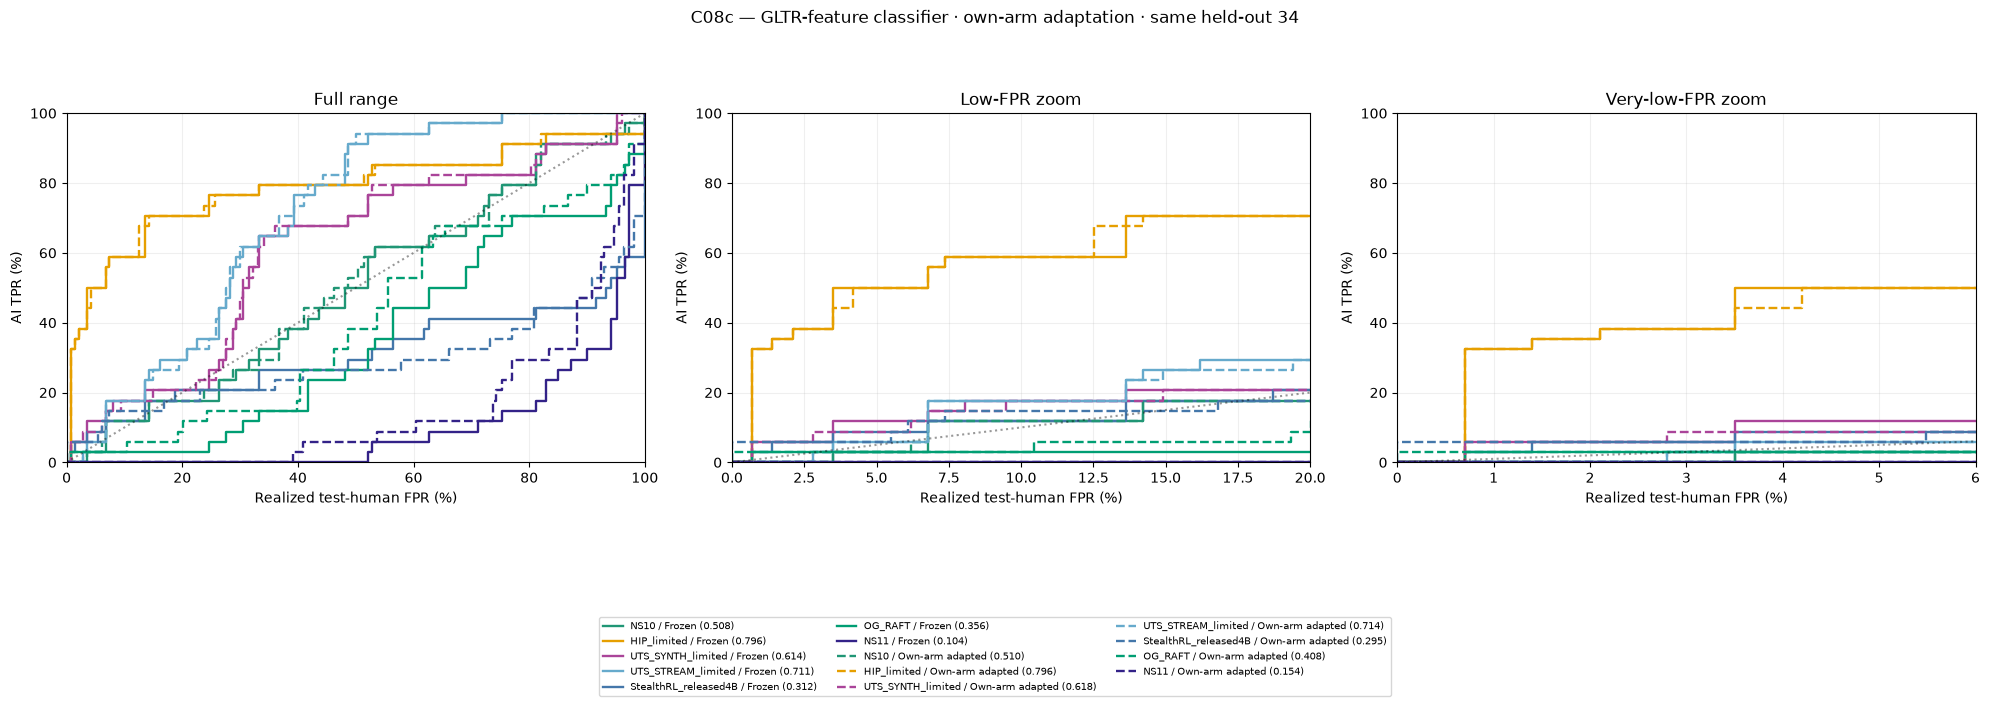

Saved: ../results/causal/C08c_GLTR_competitors_RAFT_NS11_v1
Frozen already is the RAID-only head; there is no separate neural continuation step.


In [5]:
# Own-arm adaptation: fixed GPT-2 features and original train-only scaler.
all_rows=[];all_curves=[];all_ops=[];changes=[]
fr=evaluate(frozen_scores.loc[frozen_scores.arm.isin(['Human',*selected])],held,'Frozen') if selected else None
with lock():
    for arm in selected:
        folder=OUT/'adaptation'/arm;folder.mkdir(parents=True,exist_ok=True)
        extra=features[arm].loc[features[arm].case_id.isin(chosen)].sort_values('case_id')
        fit=pd.concat([trf,extra],ignore_index=True)
        assert len(extra)==20
        freeze(folder/'fit_inputs.json',dict(rows=fit[['source_id','label','text_sha',*FEATURES]].to_dict('records'),
            classifier_parameters=repr(frozen.get_params()),extractor=spec))
        path=folder/'adapted.joblib'
        if path.exists():head=joblib.load(path)
        else:
            head=clone(frozen)
            with warnings.catch_warnings():
                warnings.simplefilter('error',ConvergenceWarning)
                head.fit(scaler.transform(fit[FEATURES]),fit.label.astype(int))
            tmp=path.with_suffix('.tmp');joblib.dump(head,tmp);os.replace(tmp,path)
        e=features[arm].loc[features[arm].case_id.isin(held)]
        scores=pd.concat([scored_frame(head,humans),scored_frame(head,e)],ignore_index=True)
        csv(scores,folder/'heldout34_and_human_scores.csv')
        ev=evaluate(scores,held,'Own-arm adapted')
        all_rows.append(ev[0]);all_curves+=ev[1];all_ops.append(ev[3])
        for splitname,f in ev[4].items():csv(f,folder/f'{splitname}_human_scores.csv')
        d=ev[2][arm]-fr[2][arm]
        draws=np.random.default_rng(SEED).integers(0,34,size=(5000,34))
        lo,hi=np.quantile(d[draws].mean(1),[.025,.975])
        changes.append(dict(arm=arm,comparison='Own-arm adapted minus frozen',delta_AUROC=d.mean(),ci_low=lo,ci_high=hi))
        print(arm,': adapted and saved',flush=True)
if selected:
    all_rows.insert(0,fr[0]);all_curves=fr[1]+all_curves;all_ops.insert(0,fr[3])
    result=pd.concat(all_rows,ignore_index=True)
    csv(result,OUT/'adapted34_summary.csv')
    csv(pd.concat(all_ops),OUT/'adapted34_operating_points.csv')
    csv(pd.concat([x[2] for x in all_curves]),OUT/'adapted34_staircases.csv')
    csv(pd.DataFrame(changes),OUT/'adapted34_paired_changes.csv')
    display(result.round(6));display(pd.DataFrame(changes).round(6))
    plot(all_curves,'C08c — GLTR-feature classifier · own-arm adaptation · same held-out 34','C08c_GLTR_adaptation34')
else:print('No non-OG arm has frozen AUROC below .8; no adaptation fitted.')
print('Saved:',OUT)
print('Frozen already is the RAID-only head; there is no separate neural continuation step.')
